# EYE FOR BLIND
## Upgrad Cohort
- C31

## Student Name, email
- SAI MITRA JANDHYALA, mitra.jandhyala@gmail.com

## Problem statement: 
In this capstone project, a deep learning model needs to be created which can explain the contents of an image in the form of speech through caption generation with an attention mechanism on Flickr8K dataset. This kind of model is a use-case for blind people so that they can understand any image with the help of speech. The caption generated through a CNN-RNN model will be converted to speech using a text to speech library.

In [1]:
#Import all the required libraries

!pip install requests
!pip install spacy
!pip install wordcloud

#Data processing
import numpy as np
import pandas as pd

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.image as pltImage

# Image Directory/File access
import pathlib
import os
import PIL
import zipfile
import glob as glob

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten
from tensorflow.keras.layers import BatchNormalization, Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras.layers import Rescaling, Reshape
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.python.framework.ops import Tensor

# NLP
# import spacy

import nltk
from nltk import FreqDist
from collections import Counter

# train test split
from sklearn.model_selection import train_test_split

#model = spacy.load("en_core_web_sm")

You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.


In [2]:
# to suppress warnings
import warnings
warnings.filterwarnings(action='ignore')

#pd.set_option('display.width', 1000)

## Enabling Eager Execution seems to be critical for capturing data from Tensorflow Tensors during dataset generation

- Data sent to Tensor flow framework is maintained internally by it for computing it in a graph.

In [3]:
if tf.executing_eagerly() == False:
  tf.compat.v1.enable_eager_execution()

print(f'Is EE Enabled ? {tf.executing_eagerly()}')

Is EE Enabled ? True


# Data preparation

## Data Extraction

In [4]:
# function to extract dataset if its already not extracted
def extract_dataset(drive_path, data_folder):
    if (os.path.exists(drive_path+'/archive.zip')) and (os.path.exists(drive_path+data_folder) == False):
      zipfd = zipfile.ZipFile(drive_path+'/archive.zip','r')
      zipfd.extractall(drive_path+data_folder+'/')
      zipfd.close()

## Note: is_google_drive to be set to True if running on Google colab.

In [5]:
is_google_drive = False

In [6]:
if is_google_drive:
  from google.colab import drive
  content_root = '/content/gdrive'
  drive.mount(content_root)
  drive_path = '<add google drive path where the archive.zip data set is present>'
else:
  drive_path = '.'

data_folder = '/archive'

In [7]:
# extract the data (unzip)
extract_dataset(drive_path,data_folder)

print('Data Folder Path is {}'.format(drive_path + data_folder))

Data Folder Path is ./archive


## Data understanding





### Import the dataset and read image & captions into two seperate variables

#### Import Image Paths

In [8]:
#Importing the dataset and reading images
images_folder = drive_path + data_folder + '/Images'

all_imgs = glob.glob(images_folder + '/*.jpg',recursive=True)

# convert all the image Paths to normalized (unix style) form
all_imgs = list(map(lambda x: x.replace("\\","/"), all_imgs))


print("The total images present in the dataset: {}".format(len(all_imgs)))

The total images present in the dataset: 8091


#### Import Captions

In [9]:
#Load captions into Dataframe
captions_file_path = drive_path + data_folder + '/captions.txt'

captions_dataset = pd.read_csv(captions_file_path, sep=',')

# lets put the absolute file path of each image for easy lookup

# lets create another column for holding image path by prefixing the path
captions_dataset['image_path'] = images_folder + '/' + captions_dataset.image

#lets see the first few records
captions_dataset.head(10)

,image,caption,image_path
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...,./archive/Images/1000268201_693b08cb0e.jpg
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .,./archive/Images/1000268201_693b08cb0e.jpg
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .,./archive/Images/1000268201_693b08cb0e.jpg
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...,./archive/Images/1000268201_693b08cb0e.jpg
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...,./archive/Images/1000268201_693b08cb0e.jpg
5,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting,./archive/Images/1001773457_577c3a7d70.jpg
6,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...,./archive/Images/1001773457_577c3a7d70.jpg
7,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...,./archive/Images/1001773457_577c3a7d70.jpg
8,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...,./archive/Images/1001773457_577c3a7d70.jpg
9,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .,./archive/Images/1001773457_577c3a7d70.jpg


#### Cross checking if images mentioned in the captions.txt are all part of Images

In [10]:
images_in_captions = set(captions_dataset.image_path)
images_in_folder = set(all_imgs)

print(f'Any difference in the images between the Images folder and the captions.txt: {len(images_in_folder.difference(images_in_captions)) != 0}')

Any difference in the images between the Images folder and the captions.txt: False


## Inferences
- Images count and Captions count tally which means the Dataset is proper

In [11]:
#A general utility to visualize both the images & text present in the dataset
def visualize_images_with_captions(images_paths, captions_list, render_size=(40,120),fontsize=30, subplot_wspace=0.3):
  
  fig = plt.figure(figsize=render_size)

  number_of_images = len(images_paths)

  for index, image_path_selected in enumerate(images_paths):
    image = pltImage.imread(image_path_selected)
    ax1 = plt.subplot(number_of_images,2,2*index+1)
    ax1.axis('off')
    image_name = image_path_selected[image_path_selected.rfind("/")+1:]
    ax1.set_title(f'Image {index+1}: {image_name}')
    ax1.imshow(image)

    ax2 = plt.subplot(number_of_images,2,2*index+2)
    ax2.axis('off')
    y_step = 0.2
    y_pos = 0.9
    for caption in captions_list[index]:
      ax2.text(0, y_pos, caption, fontsize=fontsize)
      y_pos -= y_step
    ax2.text(0,y_pos, '-'*50, fontsize=fontsize)

  plt.tight_layout()
  plt.subplots_adjust(wspace=subplot_wspace)
  plt.axis('off')
  plt.show()

### Visualise both the images & text present in the dataset 
- Lets visualize a random set of 20 images along with their captions

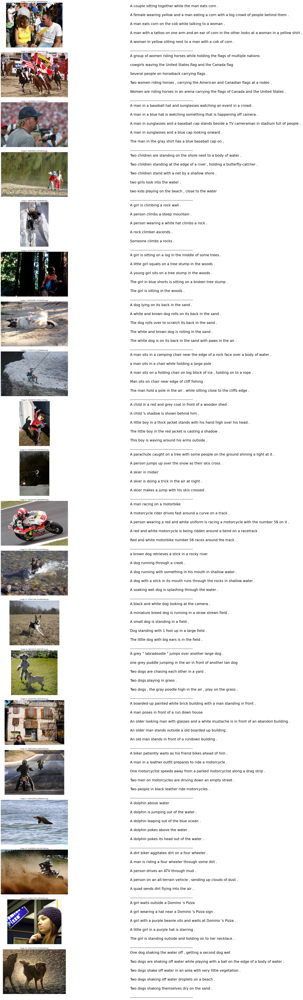

In [12]:
num_random_images = 20
image_paths_count = len(all_imgs)
random_index = np.random.randint(image_paths_count)

image_paths = []
captions_list = []
for i in range(num_random_images):
  random_index = np.random.randint(image_paths_count)
  image_path = all_imgs[random_index]
  image_paths.append(image_path)

  captions_for_image = list(captions_dataset[captions_dataset.image_path == image_path]['caption'])
  captions_list.append(captions_for_image)

visualize_images_with_captions(image_paths, captions_list, render_size=(40,120), fontsize=30)

## Inferences
- Each image has 5 captions
- Each caption describes the image in a slightly different manner

In [13]:
# read 300 records in the dataset
captions_dataset[:300]

,image,caption,image_path
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...,./archive/Images/1000268201_693b08cb0e.jpg
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .,./archive/Images/1000268201_693b08cb0e.jpg
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .,./archive/Images/1000268201_693b08cb0e.jpg
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...,./archive/Images/1000268201_693b08cb0e.jpg
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...,./archive/Images/1000268201_693b08cb0e.jpg
...,...,...,...
295,1077546505_a4f6c4daa9.jpg,A boy in blue shorts slides down a slide into ...,./archive/Images/1077546505_a4f6c4daa9.jpg
296,1077546505_a4f6c4daa9.jpg,A boy in blue swimming trunks slides down a ye...,./archive/Images/1077546505_a4f6c4daa9.jpg
297,1077546505_a4f6c4daa9.jpg,A boy rides down a slide into a small backyard...,./archive/Images/1077546505_a4f6c4daa9.jpg
298,1077546505_a4f6c4daa9.jpg,A boy sliding down a slide into a pool with co...,./archive/Images/1077546505_a4f6c4daa9.jpg


### Create a dataframe which summarizes the image, path & captions as a dataframe
- Create a dataframe which summarizes the image, path & captions as a dataframe

- Each image id has 5 captions associated with it therefore the total dataset should have 40455 samples.

In [14]:
# we already created a dataset from captions and appended image path too. 
# lets re-use this data set to create the main dataset
df = captions_dataset.copy()
#df = pd.DataFrame(list(zip(all_img_id, all_img_vector,annotations)),columns =['ID','Path', 'Captions']) 
df.rename(columns={'image':'ID', 'image_path':'Path', 'caption':'Captions'}, inplace=True)
df

,ID,Captions,Path
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...,./archive/Images/1000268201_693b08cb0e.jpg
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .,./archive/Images/1000268201_693b08cb0e.jpg
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .,./archive/Images/1000268201_693b08cb0e.jpg
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...,./archive/Images/1000268201_693b08cb0e.jpg
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...,./archive/Images/1000268201_693b08cb0e.jpg
...,...,...,...
40450,997722733_0cb5439472.jpg,A man in a pink shirt climbs a rock face,./archive/Images/997722733_0cb5439472.jpg
40451,997722733_0cb5439472.jpg,A man is rock climbing high in the air .,./archive/Images/997722733_0cb5439472.jpg
40452,997722733_0cb5439472.jpg,A person in a red shirt climbing up a rock fac...,./archive/Images/997722733_0cb5439472.jpg
40453,997722733_0cb5439472.jpg,A rock climber in a red shirt .,./archive/Images/997722733_0cb5439472.jpg


### Create a list which contains all the captions & path

In [15]:
#Create a list which contains all the captions
annotations=list(df['Captions'])

# we have captured the original captions in 'annotations' variable
# now we will modify the dataframe to mark start and end tags to each cpation
#add the <start> & <end> token to all those captions as well
df['Captions'] = df['Captions'].apply(lambda x: '<start> ' + x.lower() + ' <end>')

#Create a list which contains all the path to the images
all_img_path=list(set(df['Path']))

print("Total captions present in the dataset: "+ str(len(annotations)))
print("Total images present in the dataset: " + str(len(all_img_path)))

Total captions present in the dataset: 40455
Total images present in the dataset: 8091


### Visualise the top 30 occuring words in the captions

In [16]:
#Create the vocabulary & the counter for the captions
# we are lowering the case of words to capture the frequency in a case-insestive way
all_captions = list(annotations)
vocabulary= [word.lower() for caption in all_captions for word in caption.split()]
val_count=Counter(vocabulary)
val_count

Counter({'a': 62986,
         'child': 1545,
         'in': 18974,
         'pink': 735,
         'dress': 348,
         'is': 9345,
         'climbing': 502,
         'up': 1260,
         'set': 108,
         'of': 6713,
         'stairs': 109,
         'an': 2432,
         'entry': 1,
         'way': 50,
         '.': 36577,
         'girl': 3328,
         'going': 149,
         'into': 1074,
         'wooden': 284,
         'building': 510,
         'little': 1768,
         'playhouse': 6,
         'the': 18418,
         'to': 3173,
         'her': 1178,
         'cabin': 4,
         'black': 3832,
         'dog': 8136,
         'and': 8851,
         'spotted': 37,
         'are': 3504,
         'fighting': 132,
         'tri-colored': 14,
         'playing': 2008,
         'with': 7765,
         'each': 430,
         'other': 773,
         'on': 10743,
         'road': 388,
         'white': 3940,
         'brown': 2563,
         'spots': 29,
         'staring': 57,
         'at': 

### Visualizing top 30 words using wordcloud

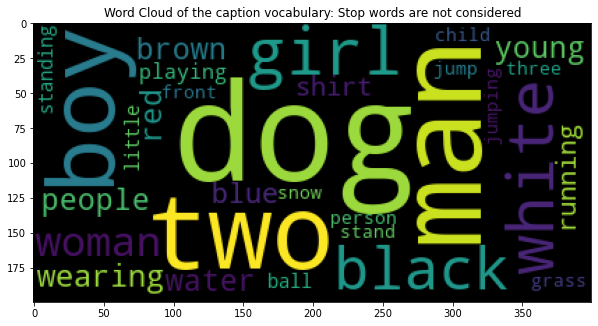

Overall frequency of words: Includes stop words


[('a', 62986),
 ('.', 36577),
 ('in', 18974),
 ('the', 18418),
 ('on', 10743),
 ('is', 9345),
 ('and', 8851),
 ('dog', 8136),
 ('with', 7765),
 ('man', 7265),
 ('of', 6713),
 ('two', 5638),
 ('white', 3940),
 ('black', 3832),
 ('boy', 3581),
 ('are', 3504),
 ('woman', 3402),
 ('girl', 3328),
 (',', 3232),
 ('to', 3173),
 ('wearing', 3062),
 ('at', 2914),
 ('people', 2883),
 ('water', 2783),
 ('red', 2672),
 ('young', 2630),
 ('brown', 2563),
 ('an', 2432),
 ('his', 2357),
 ('blue', 2268)]

In [17]:
#Visualise the top 30 occuring words in the captions
freqDist_captions_vocab = FreqDist(vocabulary)

# Top n words from processed text
from wordcloud import WordCloud
wordcloud = WordCloud(max_words=30, min_word_length=1, collocations=False, stopwords=None)
wc = wordcloud.generate(' '.join(vocabulary))
fig = plt.figure(1, figsize=(10,20))
plt.title('Word Cloud of the caption vocabulary: Stop words are not considered')
plt.imshow(wc)
plt.show()
print('Overall frequency of words: Includes stop words')
freqDist_captions_vocab.most_common(30)

## Inferences
- Stopwords dominate as usual
- Wordcloud shows that words like two, dog, boy, girl, people playing are frequent which indicates the kind of photos people usually upload on social media
- Pet dogs, sports, activities etc are observed a lot in the images

## Lets glance at the data set we have now as we marked each caption with <start> and <end> tags to act as RNN delimiters

In [18]:
df.head(5)

,ID,Captions,Path
0,1000268201_693b08cb0e.jpg,<start> a child in a pink dress is climbing up...,./archive/Images/1000268201_693b08cb0e.jpg
1,1000268201_693b08cb0e.jpg,<start> a girl going into a wooden building . ...,./archive/Images/1000268201_693b08cb0e.jpg
2,1000268201_693b08cb0e.jpg,<start> a little girl climbing into a wooden p...,./archive/Images/1000268201_693b08cb0e.jpg
3,1000268201_693b08cb0e.jpg,<start> a little girl climbing the stairs to h...,./archive/Images/1000268201_693b08cb0e.jpg
4,1000268201_693b08cb0e.jpg,<start> a little girl in a pink dress going in...,./archive/Images/1000268201_693b08cb0e.jpg


## Pre-Processing the captions


### Create the tokenized vectors by tokenizing the captions fore ex :split them using spaces & other filters.
- Replace all other words with the unknown token "UNK" .
- This gives us a vocabulary of all of the unique words in the data. Keep the total vocaublary to top 5,000 words for saving memory. 

In [19]:
# create the tokenizer
captions_vocab_limit = 5000

# create tokenizer with a limit of words and replacement of unknown words with <UNK>
tokenizer = tf.keras.preprocessing.text.Tokenizer(
    num_words=captions_vocab_limit,
    filters='!\"#$%&\(\)\*\+.,-/:;=?@\[\\\]^_`{|}~',
    oov_token='<UNK>')

tokenizer.fit_on_texts(df.Captions)

### Create word-to-index and index-to-word mappings and Pad all sequences to be the same length as the longest one.

In [20]:
# Create word-to-index and index-to-word mappings.
tokenizer.word_index['<pad'] = 0
tokenizer.index_word[0] = '<pad>'

In [21]:
# Create a word count of tokenizer to visulize the Top 30 occuring words after text processing
freqDist_captions_vocab = FreqDist(tokenizer.word_counts)
freqDist_captions_vocab.most_common(30)

[('a', 62992),
 ('<start>', 40455),
 ('<end>', 40455),
 ('in', 18986),
 ('the', 18419),
 ('on', 10745),
 ('is', 9345),
 ('and', 8862),
 ('dog', 8138),
 ('with', 7765),
 ('man', 7274),
 ('of', 6723),
 ('two', 5642),
 ('white', 3959),
 ('black', 3848),
 ('boy', 3581),
 ('are', 3504),
 ('woman', 3402),
 ('girl', 3328),
 ('to', 3176),
 ('wearing', 3062),
 ('at', 2915),
 ('people', 2883),
 ('water', 2790),
 ('red', 2691),
 ('young', 2630),
 ('brown', 2578),
 ('an', 2432),
 ('his', 2357),
 ('blue', 2279)]

## Inferences
= < start > and < end > top the list as we modified each caption to have these both words in the beginning and the end respectively

## Lets see which image has the longest caption in the given dataset

In [22]:
longest_caption = df.Captions.str.len().sort_values(ascending=False)
longest_caption_index = longest_caption.index[0]
longest_caption_image_df = df[df.index == longest_caption_index]
longest_caption_image_df.head()

,ID,Captions,Path
8049,2354456107_bf5c766a05.jpg,<start> an african-american man wearing a gree...,./archive/Images/2354456107_bf5c766a05.jpg


###  Lets render the image that has the longest caption

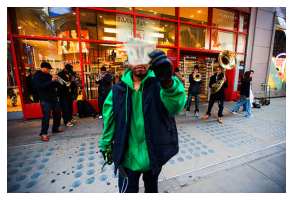

<start> an african-american man wearing a green
sweatshirt and blue vest is holding up 2 dollar
bills in front of his face , while standing on a
busy sidewalk in front of a group of men playing
instruments . <end>


In [23]:
import textwrap

longest_caption_image_path = longest_caption_image_df.iloc[0]['Path']
longest_caption = longest_caption_image_df.iloc[0]['Captions']
image = pltImage.imread(longest_caption_image_path)
fig = plt.figure(figsize=(5,5))
ax1 = plt.axes()
image = pltImage.imread(longest_caption_image_path)
ax1.imshow(image)
plt.axis('off')
plt.show()

tw = textwrap.TextWrapper(width = 50)
longest_caption_textwrapped = tw.wrap(text = longest_caption)
for t in longest_caption_textwrapped:
  print(t) 

In [24]:
# convert words into sequences
caption_word_sequences = tokenizer.texts_to_sequences(df.Captions)

# Pad each vector to the max_length of the captions ^ store it to a variable
cap_vector = tf.keras.preprocessing.sequence.pad_sequences(caption_word_sequences, maxlen=None,padding='post', dtype='int32')

# maintain a map of caption string to caption vector
caption_vector_map = {k:cap_vector[i] for i,k in enumerate(df.Captions)}

print("The shape of Caption vector is :" + str(cap_vector.shape))

The shape of Caption vector is :(40455, 39)


## Pre-processing the images

- Resize them into the shape of (299, 299)
- Normalize the image within the range of -1 to 1, such that it is in correct format for InceptionV3. 

In [25]:
# general utility to load an image given its path by passing it through inception model and returning the inception output (image tensor)
image_height = 299
image_width = 299

def load_image(image_path):
    image_binary_original = tf.io.read_file(image_path)
    image_binary_jpeg = tf.io.decode_jpeg(image_binary_original, channels=3)
    # resize
    image_binary_jpeg_resized = tf.keras.layers.Resizing(image_height, image_width)(image_binary_jpeg)
    # pre-process the image values within the range of -1 and 1 to make it fit to feed inception model
    image_binary_jpeg_resized_inception_ready = tf.keras.applications.inception_v3.preprocess_input(image_binary_jpeg_resized)
    return image_binary_jpeg_resized_inception_ready, image_path

def get_image_tensor(image_path):
    image_binary_original = tf.io.read_file(image_path)
    image_binary_jpeg = tf.io.decode_jpeg(image_binary_original, channels=3)
    # resize
    image_binary_jpeg_resized = tf.keras.layers.Resizing(image_height, image_width)(image_binary_jpeg)
    # pre-process the image values within the range of -1 and 1 to make it fit to feed inception model
    image_binary_jpeg_resized_inception_ready = tf.keras.applications.inception_v3.preprocess_input(image_binary_jpeg_resized)
    return image_binary_jpeg_resized_inception_ready

## Gather image binaries in Tensor Flow format having image_path and raw binary image resized to 299X299X3

In [26]:
# images repeat due to 5 captions per image.
# hence we capture the unique paths and load the image_path_dataset
batch_size = 32
image_path_dataset = tf.data.Dataset.from_tensor_slices(list(set(df.Path)))
image_binary_dataset = image_path_dataset.map(load_image).batch(batch_size)

2022-08-11 08:56:39.531247: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:39] Overriding allow_growth setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
2022-08-11 08:56:39.531330: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14803 MB memory:  -> device: 0, name: Quadro RTX 5000, pci bus id: 0000:1e:00.0, compute capability: 7.5


## Load the pretrained Imagenet weights of Inception net V3

- To save the memory(RAM) from getting exhausted, extracting the features of the images using the last layer of pre-trained model. Including this as part of training will lead to higher computational time.

- The shape of the output of this layer is 8x8x2048.



In [27]:
# inception V3 model
image_model = tf.keras.applications.InceptionV3(include_top=False,weights='imagenet')

new_input = image_model.input
# pull the output from the last layer (-1)
hidden_layer = image_model.layers[-1].output

# build a model out of inception v3
image_features_extract_model = keras.Model(new_input, hidden_layer)

## Lets check the shape of the output of feature vector from the inception model.
- We do have idea that its CNN model so the image size will be reduced and will have n x n shape and the features will be expanded to 2048
- So the shape we see would be (batch_size, 8, 8, 2048)

In [28]:

for batched_images, batched_image_paths in image_binary_dataset:
  feature_vector_batch = image_features_extract_model(batched_images)
  print(f'Output from Inception Model is of the shape: {feature_vector_batch.shape}')
  break

2022-08-11 08:56:42.353445: I tensorflow/stream_executor/cuda/cuda_dnn.cc:377] Loaded cuDNN version 8302


Output from Inception Model is of the shape: (32, 8, 8, 2048)


## Extract features out of images by passing them through the inception model
- inception model would give us a rich feature set on which we can build useful features

In [29]:
# code to apply the feature_extraction model to the earlier created dataset which contained images & their respective paths
# feature shape is in order of (batch_size, 8*8, 2048) i.e, the 8 x 8 images from V3 are flattended out to 64 length vectors each
image_path_feature_vector_map = {}
iter = 0
total_iterations = int(np.ceil(len(all_imgs)/batch_size))
show_progress_percentage = 5
progress_after_iterations = (total_iterations * show_progress_percentage)//100

print(f'Total Iterations: {total_iterations}')
for batched_images, batched_image_paths in image_binary_dataset:
  #print(f'Processing Batch {iter+1}...START')
  feature_vector_batch = image_features_extract_model(batched_images)
  # we need to crunch each 8x8 image in a linear space (vector)
  existing_shape = feature_vector_batch.shape
  # shape[0] is batch size; we need it
  # shape[1] & shape[2] are convoluted image shapes which have to be flattened out
  # shape[3] is the number of features extracted; we retain it
  feature_vector_batch = tf.reshape(
      feature_vector_batch, 
      shape=(
      feature_vector_batch.shape[0],
      -1,
      feature_vector_batch.shape[3]
  ))
  #print(f'Processing Batch {iter+1}...FEATURE VECTORS RESHAPE DONE.')
  # pack the paths and features into a tuple and extract to build the image_path_feature_vector_map
  for p,i in zip(batched_image_paths, feature_vector_batch):
    image_path_feature_vector_map[p.numpy().decode("utf-8")] = i.numpy()
  #print(f'Processing Batch {iter+1}...END')
  iter += 1
  if iter%progress_after_iterations == 0:
    print(f'Progress: {np.round(iter*100/total_iterations,2)}%')
  
print(f'Total Images captured: {len(image_path_feature_vector_map.keys())}')

Total Iterations: 253
Progress: 4.74%
Progress: 9.49%
Progress: 14.23%
Progress: 18.97%
Progress: 23.72%
Progress: 28.46%
Progress: 33.2%
Progress: 37.94%
Progress: 42.69%
Progress: 47.43%
Progress: 52.17%
Progress: 56.92%
Progress: 61.66%
Progress: 66.4%
Progress: 71.15%
Progress: 75.89%
Progress: 80.63%
Progress: 85.38%
Progress: 90.12%
Progress: 94.86%
Progress: 99.6%
Total Images captured: 8091


## CHECKPOINT 1 : Save the hardwork
- Save important data objects we have collected so far
  all_imgs, captions_dataset, df
- Save caption_vector_map using numpy save
- Using numpy.save, save the image feature vector map into image files each containing the numpy vector

In [30]:
# helps clean a non empty folder using rmtree
import shutil

def create_folder(folder_name):
  if os.path.exists(folder_name) == False:
    os.makedirs(folder_name)
  else:
    shutil.rmtree(folder_name)
    os.makedirs(folder_name)

In [31]:
# create a directory called 'extracted_data'
extracted_data_folder = drive_path + data_folder +'/extracted_data/'
create_folder(extracted_data_folder)

# write the important data objects into extracted_data folder
with open(extracted_data_folder+'all_imgs.txt', 'w') as all_imgs_file:
  all_imgs_file.write(str(all_imgs))

captions_dataset.to_csv(extracted_data_folder+'captions_dataset.csv')
df.to_csv(extracted_data_folder+'df.csv')

# create a directory called 'feature_vectors'
feature_vectors_dir_path = drive_path + data_folder +'/feature_vectors/'
create_folder(feature_vectors_dir_path)

for img_path in image_path_feature_vector_map:
  image_name = img_path[img_path.rfind("/")+1:]
  with open(feature_vectors_dir_path + image_name + '.bin', 'wb') as image_file:
    np.save(image_file, image_path_feature_vector_map[img_path])
    image_file.close()

## RESTORE FROM CHECKPOINT 1
- Lets read back the feature map from json file we had created

### Note: Set RESTORE_FROM_CHECKPOINT1 to True to revive the image feature vector map from stored binary files

In [32]:
captions_dataset = pd.read_csv(extracted_data_folder+'captions_dataset.csv')
captions_dataset.drop(['Unnamed: 0'], axis=1, inplace=True)
captions_dataset = captions_dataset.reindex()

In [33]:
# general utility to restore CSV file
def restore_csv(csv_file):
  ds = pd.read_csv(csv_file)
  ds.drop(['Unnamed: 0'], axis=1, inplace=True)
  ds = ds.reindex()
  return ds

In [34]:
# to convert string representation of list
import ast

RESTORE_FROM_CHECKPOINT1 = True

if RESTORE_FROM_CHECKPOINT1:
  extracted_data_folder = drive_path + data_folder +'/extracted_data/'

  # restore all_imgs
  with open(extracted_data_folder+'all_imgs.txt', 'r') as all_imgs_file:
    all_imgs = eval(all_imgs_file.read())

  #restore pandas Dataframes from csv files
  captions_dataset = restore_csv(extracted_data_folder+'captions_dataset.csv')
  df = restore_csv(extracted_data_folder+'df.csv')

  feature_vectors_dir_path = drive_path + data_folder +'/feature_vectors/'

  image_feature_vectors = glob.glob(feature_vectors_dir_path + '/*.bin',recursive=True)
  print(f'Total image vectors saved: {len(image_feature_vectors)}')

  # convert all the image Paths to normalized (unix style) form
  image_feature_vectors = list(map(lambda x: x.replace("\\","/"), image_feature_vectors))

  image_path_feature_vector_map = {}

  for image_binary in image_feature_vectors:
    image_name = image_binary[image_binary.rfind("/")+1:]
    image_name = image_name[:image_name.rfind(".bin")]
    image_path_feature_vector_map[drive_path + data_folder + '/Images/'+image_name] = np.load(image_binary)

  print(f'Total image vectors restored: {len(image_path_feature_vector_map)}')

Total image vectors saved: 8091
Total image vectors restored: 8091


## Dataset creation

In [35]:
# train test split should split a common dataset having an image and its five captions as one unit
# we have to create a dataset that has an image path and a list of captions associated with as one data point
# to illustrate, each record would be (image_path, [c1, c2, c3, c4, c5]) where X = image_path & Y = [c1, c2, c3, c4, c5]

# dataset to be created for train test splitting in 80-20

# first lets collect the images from the data set. That will be our X
X = list(set(df.Path))

# Y will be our caption list per image
Y = []
# lets iterate through each image and collect all the captions associated with it in a list
for x in X:
  y = list(df[df.Path == x]['Captions'])
  # append the list of captions as predicted value to Y
  Y.append(y)

print(f'Size of images {len(X)}, Size of captions {len(Y)}')

Size of images 8091, Size of captions 8091


## Lets visualize our images (X) and their captions (Y) which we put together for train test split

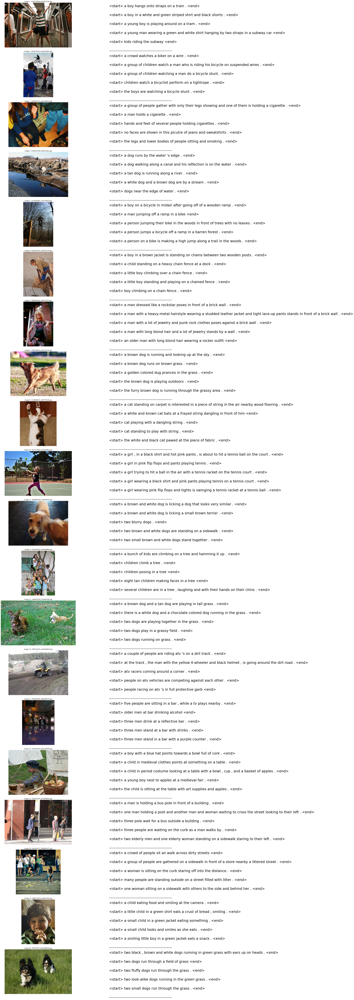

In [36]:
num_random_images = 20
image_paths_count = len(X)
random_index = np.random.randint(image_paths_count)

image_paths = []
captions_list = []
for i in range(num_random_images):
  random_index = np.random.randint(image_paths_count)
  image_path = X[random_index]
  image_paths.append(image_path)

  captions_for_image = Y[random_index]
  captions_list.append(captions_for_image)

visualize_images_with_captions(image_paths, captions_list, render_size=(40,120), fontsize=30)

## Inferences
- The caption changes are done.
- Prefixed with < start >
- Suffixed with < end >

### Apply train_test_split on both image path & captions to create the train & test list. Create the train-test spliit using 80-20 ratio & random state = 42
- lets use our X & Y to split them into train and test sets with shuffling

In [37]:
path_train, path_test, cap_train, cap_test = train_test_split(X, Y, train_size=0.8,shuffle=True, random_state=42)

In [38]:
# now we have train and test set split along with their captions.
# captions are 5, image is one
# hence, we have to expand the image_path vector one for every caption
def expand_image_caption_datasets(image_paths_ds, captions_ds):
  path_train_expanded = []
  cap_train_expanded = []

  for i, captions in enumerate(captions_ds):
    if isinstance(captions, list):
      cap_train_expanded.extend(captions)
      path_train_expanded.extend([image_paths_ds[i]]*len(captions))
    else:
      cap_train_expanded.append(captions)
      path_train_expanded.append(image_paths_ds[i])
  return path_train_expanded, cap_train_expanded

path_train, cap_train = expand_image_caption_datasets(path_train, cap_train)
path_test, cap_test = expand_image_caption_datasets(path_test, cap_test)

In [39]:
print("Training data for images: " + str(len(path_train)))
print("Testing data for images: " + str(len(path_test)))
print("Training data for Captions: " + str(len(cap_train)))
print("Testing data for Captions: " + str(len(cap_test)))

Training data for images: 32360
Testing data for images: 8095
Training data for Captions: 32360
Testing data for Captions: 8095


### Create a function which maps the image path to their feature.

In [40]:
# Create a function which maps the image path to their feature. 
# This function will take the image_path & caption and return it's feature & respective caption.
def map_func(image_path, caption):
  img_tensor = image_path_feature_vector_map[image_path.decode('UTF-8')]
  caption_vector = caption_vector_map[caption.decode('UTF-8')]
  return img_tensor, caption_vector

### Dataset creation
- Create a builder function to create train & test dataset & apply the function created earlier to transform the dataset
-Shuffle and batch while building the dataset

In [41]:
# create a builder function to create dataset which takes in the image path & captions as input
# This function should transform the created dataset(img_path,cap) to (features,cap) using the map_func created earlier
BATCH_SIZE = 32

def gen_dataset(image_paths, captions):
    # create the dataset & transform it
    # iterate through each image and each of its captions and create 5 datapoints (image with each of its 5 captions)
    #tf.data.Dataset.
    tensor_slices_ds = tf.data.Dataset.from_tensor_slices((image_paths, captions))
    dataset = tensor_slices_ds.map(lambda item1, item2: tf.numpy_function(
          map_func, inp=[item1, item2], Tout=[tf.float32, tf.int32]),
          num_parallel_calls=tf.data.AUTOTUNE)
    
    BUFFER_SIZE = len(image_paths)
    dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

    print(dataset)
    return dataset

In [42]:
train_dataset = gen_dataset(path_train,cap_train)
test_dataset = gen_dataset(path_test,cap_test)

<PrefetchDataset shapes: (<unknown>, <unknown>), types: (tf.float32, tf.int32)>
<PrefetchDataset shapes: (<unknown>, <unknown>), types: (tf.float32, tf.int32)>


# Image and Caption dataset shape
- The shape of each image in the dataset after building should be (batch_size, 8*8, 2048)
- The shape of each caption in the dataset after building should be(batch_size, max_len)

In [43]:
sample_img_batch, sample_cap_batch = next(train_dataset.as_numpy_iterator())

print(sample_img_batch.shape)  #(batch_size, 8*8, 2048)
print(sample_cap_batch.shape) #(batch_size,max_len)

2022-08-11 08:57:59.239000: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 10762 of 32360
2022-08-11 08:58:09.244579: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 21617 of 32360
2022-08-11 08:58:19.239900: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 31565 of 32360
2022-08-11 08:58:19.975750: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:405] Shuffle buffer filled.


(32, 64, 2048)
(32, 39)


# Model Building
- Set the parameters
- Build the Encoder, Attention model & Decoder
- We will be using L2 regularizer at strategic points to prevent overfitting
- We will be using 20% dropouts in Encoder and Decoder so as to prevent model from rote learning the train dataset

In [44]:
embedding_dim = 256 
units = 512
vocab_size = 5001 #top 5,000 words + 1
train_num_steps = len(path_train) // batch_size
test_num_steps =  len(path_test) // batch_size

# Encoder

## Encoder Hyperparameters
- L2 Regularizer with regularization parameter of 0.01
- Dropout layer which will randomly drop 20% of the outputs from the Dense layer so that the Decoder is forced to work with non-complete inputs preventing it from rote learning the dataset

In [45]:
class Encoder(keras.Model):
    def __init__(self,embed_dim):
        super(Encoder, self).__init__()
        
        #Dense layer with relu activation
        self.dense = Dense(embed_dim, 
                           activation='relu', 
                           kernel_regularizer=l2(0.01),
                           name="Encoder_Dense_1")
        self.dropout = Dropout(0.20)
        
    def call(self, features):
        features =  self.dropout(self.dense(features))# extract the features from the image shape: (batch, 8*8, embed_dim)
        return features
        
    def Model(self):
      x = keras.Input(shape=(8*8,2048))
      return keras.Model(inputs=[x], outputs=self.call(x))

In [46]:
encoder = Encoder(embedding_dim)

## Lets see the encoder model summary by passing the sample batch extracted above

In [47]:
encoder.build(input_shape=sample_img_batch.shape)
print(encoder.Model().summary())

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 64, 2048)]        0         
                                                                 
 Encoder_Dense_1 (Dense)     (None, 64, 256)           524544    
                                                                 
 dropout (Dropout)           (None, 64, 256)           0         
                                                                 
Total params: 524,544
Trainable params: 524,544
Non-trainable params: 0
_________________________________________________________________
None


# Attention model

## Attention Model Hyperparameters
- L2 Regularization in final dense layer to prevent overfitting


In [48]:
class Attention_model(keras.Model):
    def __init__(self, units):
        super(Attention_model, self).__init__()

        # Dense layer that processes the feature vector
        self.W1 = Dense(units, name="Attention_Feature_Vector_Dense_Layer")

        # Dense layer that processes the hidden layer from RNN
        self.W2 = Dense(units, name="Attention_Hidden_Layer_Dense_Layer")

        # Dense layer which is the output of the Attention (score) with l2 regularizer
        self.V = Dense(1, name="Attention_Output_Dense_Layer", kernel_regularizer=l2(0.01))

        self.units=units

    def call(self, inputs):
        features = inputs[0]
        hidden = inputs[1]
        # features shape: (batch_size, 8*8, embedding_dim) = 32, 64, 256
        # hidden shape: (batch_size, hidden_size) = 32, 512
        # Expand the hidden shape to shape: (batch_size, 1, hidden_size) = 32, 1, 512
        # 32, 64, 256 -> W1 -> 32, 64, 512
        # 32,  1, 512 -> W2 -> 32,  1, 512
        
        hidden_with_time_axis =  tf.expand_dims(hidden, 1, name="Attention_Hidden_Layer_Expanded_Dims")

        # self.W1(features) would produce a shape of (32, 64, 512)
        # self.W2(hidden_with_time_axis) would produce a shape of (32, 1, 512)
        # self.V(tf.tanh(self.W1(features) + self.W2(hidden_with_time_axis))) => This will still be 32, 64, 512 as hidden input 
        # will be adding to all the 64 FVs
        # score = self.V(tf.tanh(self.W1(features) + self.W2(hidden_with_time_axis))) 
        # => This will crunch the last dimension to 1 => (batch_size, 8*8, units)
        # build score funciton to shape: (batch_size, 8*8, units)
        score = self.V(tf.tanh(self.W1(features) + self.W2(hidden_with_time_axis))) 
        # print('score shape', score.shape)

        # extract attention weights with shape: (batch_size, 8*8, 1)
        # attention weights are obtained by normalizing the weights
        attention_weights =  tf.nn.softmax(score, axis=1)
        # print('attention_weights shape', attention_weights.shape)

        # this is not a dot product but element wise multiplication of 2 tensors
        # the context vector will now be having different weights distributed across different parts of the convolution image
        context_vector =  attention_weights * features #shape: create the context vector with shape (batch_size, 8*8, embedding_dim)

        # reduce the shape to (batch_size, embedding_dim)
        # by using reduce sum we do weighted sum of all the feature values of the image. The important ones or high weight features
        # would be dominating
        context_vector = tf.reduce_sum(context_vector, axis=1)
        
        return context_vector, attention_weights
    
    def Model(self):
      x1 = keras.Input(shape=(8*8, 256))
      x2 = keras.Input(shape=(512))
      return keras.Model(inputs=[[x1,x2]], outputs=self.call([x1,x2]))

### Attention Model Summary

In [49]:
attention_model = Attention_model(units)
x1 = (batch_size,8*8, 256)
x2 = (batch_size, 512)
attention_model.build(input_shape=[x1,x2])
print(attention_model.Model().summary())

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 512)]        0           []                               
                                                                                                  
 input_3 (InputLayer)           [(None, 64, 256)]    0           []                               
                                                                                                  
 tf.expand_dims (TFOpLambda)    (None, 1, 512)       0           ['input_4[0][0]']                
                                                                                                  
 Attention_Feature_Vector_Dense  (None, 64, 512)     131584      ['input_3[0][0]']                
 _Layer (Dense)                                                                             

# Decoder

## Decoder Hyperparameters
- L2 Regularizer Dense layer connecting to output
- Droput layer added to prevent overfitting

In [50]:
class Decoder(keras.Model):
    def __init__(self, embed_dim, units, vocab_size):
        super(Decoder, self).__init__()
        self.embed_dim = embed_dim
        self.units = units
        self.vocab_size = vocab_size

        # Attention model that takes a feed of (64, 256) image vectors and (512) hidden state vector
        # and produces (256) weighted vector
        self.attention = Attention_model(units)

        # embdedding layer to tranform 5001 word vectors into (256) features
        self.embed = tf.keras.layers.Embedding(input_dim=self.vocab_size, output_dim=embed_dim, name='Encoder_Vocab_Embedding_Layer')

        self.gru = tf.keras.layers.GRU(self.units,return_sequences=True,return_state=True,recurrent_initializer='glorot_uniform', name='GRU_RNN')

        # a Dense layer that produces 512 o/ps
        self.d1 = Dense(units, name="Encoder_RNN_Dense_1", kernel_regularizer=l2(0.01))

        # add a droput layer
        self.dropout = Dropout(0.20)

        # a Dense layer that produces logits of vocab sizef
        self.d2 = Dense(vocab_size, name="Encoder_Vocab_Dense_2")

        

    def call(self,inputs):
        x = inputs[0]
        features = inputs[1]
        hidden = inputs[2]

        #create context vector & attention weights from attention model
        context_vector, attention_weights = self.attention([features,hidden])

        # expand the dimensions of context_vector obtained from Attention model
        context_vector_expanded = tf.expand_dims(context_vector, 1, name="Encoder_Attention_Output_Expanded_Dims")

        x_embed = self.embed(x)

        # Concatenate input with the context vector from attention layer. Shape: (batch_size, 1, embedding_dim + embedding_dim)
        input_to_RNN =  tf.concat([x_embed, context_vector_expanded], -1)

        # Extract the output & hidden state from GRU layer. Output shape : (batch_size, max_length, hidden_size)
        output,state = self.gru(input_to_RNN)
        output = self.dropout(self.d1(output))

        output = tf.reshape(output, (-1, output.shape[2])) # shape : (batch_size * max_length, hidden_size)

        output = self.d2(output) # shape : (batch_size * max_length, vocab_size)
        
        return output,state, attention_weights

    def Model(self):
      x = keras.Input(shape=(1))
      f = keras.Input(shape=(64, 256))
      h = keras.Input(shape=(512))
      return keras.Model(inputs=[[x,f, h]], outputs=self.call([x,f,h]))
    
    def init_state(self, batch_size):
        return tf.zeros((batch_size, self.units))

### Decoder Model summary

In [51]:
decoder = Decoder(256, 512, 5001)
x = (batch_size,1)
f = (batch_size, 64, 256)
h = (batch_size, 512)
decoder.build(input_shape=[x, f, h])
print(decoder.Model().summary())

Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_6 (InputLayer)           [(None, 64, 256)]    0           []                               
                                                                                                  
 input_7 (InputLayer)           [(None, 512)]        0           []                               
                                                                                                  
 input_5 (InputLayer)           [(None, 1)]          0           []                               
                                                                                                  
 attention_model_1 (Attention_m  ((None, 256),       394753      ['input_6[0][0]',                
 odel)                           (None, 64, 1))                   'input_7[0][0]']          

## Lets create a decoder

In [52]:
decoder=Decoder(embedding_dim, units, vocab_size)

In [53]:
features=encoder(sample_img_batch)

hidden = decoder.init_state(batch_size=sample_cap_batch.shape[0])
print('Decoder hidden shape:', hidden.shape)
dec_input = tf.expand_dims([tokenizer.word_index['<start>']] * sample_cap_batch.shape[0], 1)
print('Decoder word input shape:', dec_input.shape)

predictions, hidden_out, attention_weights= decoder([dec_input, features, hidden])

print('Feature shape from Encoder: {}'.format(features.shape)) #(batch, 8*8, embed_dim)
print('Predcitions shape from Decoder: {}'.format(predictions.shape)) #(batch,vocab_size)
print('Attention weights shape from Decoder: {}'.format(attention_weights.shape)) #(batch, 8*8, embed_dim)

predicted_ids = tf.argmax(predictions, 1).numpy()
print(f'Predicted word ids: {predicted_ids}')
print(f'Predicted words are {[tokenizer.index_word[pid] for pid in predicted_ids]}')

Decoder hidden shape: (32, 512)
Decoder word input shape: (32, 1)
Feature shape from Encoder: (32, 64, 256)
Predcitions shape from Decoder: (32, 5001)
Attention weights shape from Decoder: (32, 64, 1)
Predicted word ids: [1003 1679  226 2521 3592 2697 1003 2521 3582   34 2521 2699 1049 1920
 2458 3582 2697 2166 4014 2661 2166 4265 4379 3592 2980 3394  226 2458
 3582  226 3592 2697]
Predicted words are ['waters', 'performer', 'snowboarder', 'tool', 'topped', 'surfboards', 'waters', 'tool', 'shadowed', 'through', 'tool', 'signal', 'chest', 'carried', 'shining', 'shadowed', 'surfboards', 'cries', 'africans', 'bricks', 'cries', 'tears', 'need', 'topped', 'tinkerbell', 'siting', 'snowboarder', 'shining', 'shadowed', 'snowboarder', 'topped', 'surfboards']


## Model training & optimization


### Set the optimizer & loss object

In [54]:
optimizer = tf.keras.optimizers.Adam()

# logits because we are calculating loss on raw output of RNN
loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

### Create loss function

In [55]:
def loss_function(real, pred):
    mask = tf.math.logical_not(tf.math.equal(real, 0))
    loss_ = loss_object(real, pred)

    mask = tf.cast(mask, dtype=loss_.dtype)
    loss_ *= mask

    return tf.reduce_mean(loss_)

### Create checkpoint path

In [56]:
checkpoint_path = drive_path + data_folder + '/checkpoint'
ckpt = tf.train.Checkpoint(encoder=encoder,
                           decoder=decoder,
                           optimizer = optimizer)
ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

# Restore from latest checkpoint

In [57]:
start_epoch = 0
if ckpt_manager.latest_checkpoint:
    ckpt.restore(ckpt_manager.latest_checkpoint)
    start_epoch = int(ckpt_manager.latest_checkpoint.split('-')[-1])
    print(f'Model Restored From Checkpoint at Epoch {start_epoch}')

## Create training & testing step functions
- While creating the training step for the model, we will be using Teacher forcing
  - Teacher forcing is a technique where the target/real word is passed as the next input to the decoder instead of previous prediciton.

In [58]:
@tf.function
def train_step(img_tensor, target):
    loss = 0
    hidden = decoder.init_state(batch_size=target.shape[0])
    dec_input = tf.expand_dims([tokenizer.word_index['<start>']] * target.shape[0], 1)
    
    # training happens within the ambit of Gradient tape so has to capture the output value varies with all the input variables
    # dy/dx or differentiation needs to be done wrt to loss on all the participating variables
    with tf.GradientTape() as tape:
        # encode the image by passing it through 256 Dense layer to get shape(32, 64, 256)
        image_feature_vector = encoder(img_tensor)

        # for all the caption words from <start> to <end>, train the network
        caption_vector_size = target.shape[1]

        # We prefixed all the captions with <start> and suffixed them
        # with an <end>
        # <start> is already fed as input. Our target word should be the second 
        # word in the caption which is actually the first word in the original
        # caption set. 
        for i in range(1, caption_vector_size):

          current_word_value = target[:,i]
          # pass the first word <start>, image_feature_vector  & hidden to Decoder
          decoder_output, hidden, attention_weights = decoder([dec_input, image_feature_vector, hidden])

          step_loss = loss_function(target[:,i], decoder_output)

          loss += step_loss

          # Teacher forcing: aligning the decoder to consider actual previous output 
          dec_input = tf.expand_dims(current_word_value, 1)

    # obtain grandients of loss wrt to all the variables of the model (encoder + decoder weights)
    trainable_variables = encoder.trainable_variables + decoder.trainable_variables
    avg_loss = loss/caption_vector_size
    # gradients of slopes of all the trainable params wrt to difference between predicted and actual
    dydx_list = tape.gradient(loss, trainable_variables)
    # supply gradients to optimizer to help is close the gaps
    optimizer.apply_gradients(zip(dydx_list, trainable_variables))

    return loss, avg_loss

* While creating the test step for the model, we  will pass the previous prediciton as the next input to the decoder.

In [59]:
@tf.function
def test_step(img_tensor, target):
    loss = 0
    
    hidden = decoder.init_state(batch_size=target.shape[0])
    dec_input = tf.expand_dims([tokenizer.word_index['<start>']] * target.shape[0], 1)

    # encode the image by passing it through 256 Dense layer to get shape(32, 64, 256)
    image_feature_vector = encoder(img_tensor)

    # for all the caption words from next of <start> to <end>, train the network
    caption_vector_size = target.shape[1]

    for i in range(1, caption_vector_size):
      #current_word_value = target[:,i]
      # pass the first word <start>, image_feature_vector  & hidden to Decoder
      decoder_output, hidden, attention_weights = decoder([dec_input, image_feature_vector, hidden])
      step_loss = loss_function(target[:,i], decoder_output)
      # no teacher forcing in test step; we feed the predicted output as it is to the next RNN timestep
      # we first procure the maximum value index in the output and determine the word that it represents
      predicted_ids = tf.argmax(decoder_output, 1)
      # feed the caption vectors of each word to RNN
      # dec_input = tf.convert_to_tensor([caption_vector_map[tokenizer.index_word[pid]] for pid in predicted_ids])
      dec_input = tf.expand_dims(predicted_ids, 1)
      loss += step_loss
    
    avg_loss = loss/caption_vector_size
    return loss, avg_loss

In [60]:
def test_loss_cal(test_dataset):
    total_loss = 0
    # steps holds the total number of steps performed
    # total_loss accumulates the average loss encountered in each batch
    steps = 0
    for (batch, (img_tensor, target)) in enumerate(test_dataset):
      batch_loss, t_loss = test_step(img_tensor, target)
      total_loss += t_loss
      steps += 1
    
    # average loss is total batch loss over the number steps performed on those batches
    avg_test_loss=total_loss/steps
    return avg_test_loss

In [61]:
from tqdm import tqdm
import time

loss_plot = []
test_loss_plot = []
EPOCHS = 40

# after every 1/10th the journey keep saving the model
save_model_after_every = EPOCHS//10

# start the model from where we stopped
print(f'Model startring from epoch {start_epoch}')

best_test_loss=100
for epoch in tqdm(range(start_epoch, EPOCHS)):
    start = time.time()
    total_loss = 0

    steps = 0
    for (batch, (img_tensor, target)) in enumerate(train_dataset):
        batch_loss, t_loss = train_step(img_tensor, target)
        total_loss += t_loss
        steps += 1
    
    avg_train_loss = total_loss/steps
        
    loss_plot.append(avg_train_loss)    
    test_loss = test_loss_cal(test_dataset)
    test_loss_plot.append(test_loss)
    
    print ('For epoch: {}, the train loss is {:.3f}, & test loss is {:.3f}'.format(epoch,avg_train_loss,test_loss))
    print ('Time taken for 1 epoch {} sec\n'.format(time.time() - start))
    
    # periodic saving of the model
    if epoch %  save_model_after_every == 0:
        print(f'Saving model at epoch {epoch}, train loss is at  {avg_train_loss}')
        best_test_loss = test_loss
        ckpt_manager.save()

Model startring from epoch 0


  0%|          | 0/40 [00:00<?, ?it/s]2022-08-11 08:58:32.008419: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 13977 of 32360
2022-08-11 08:58:42.006609: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 26483 of 32360
2022-08-11 08:58:46.842728: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:405] Shuffle buffer filled.
  2%|▎         | 1/40 [04:16<2:46:35, 256.29s/it]

For epoch: 0, the train loss is 0.978, & test loss is 2.315
Time taken for 1 epoch 256.1303849220276 sec

Saving model at epoch 0, train loss is at  0.978388249874115


2022-08-11 09:02:48.294967: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 11165 of 32360
2022-08-11 09:02:58.294366: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 21873 of 32360
2022-08-11 09:03:07.851815: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:405] Shuffle buffer filled.
  5%|▌         | 2/40 [06:51<2:04:34, 196.70s/it]

For epoch: 1, the train loss is 0.776, & test loss is 2.383
Time taken for 1 epoch 154.98456525802612 sec



...

For epoch: 37, the train loss is 0.218, & test loss is 5.189
Time taken for 1 epoch 152.13682508468628 sec



2022-08-11 10:32:21.703026: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 14314 of 32360
2022-08-11 10:32:31.704247: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 27089 of 32360
2022-08-11 10:32:36.371539: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:405] Shuffle buffer filled.
 98%|█████████▊| 39/40 [1:36:18<02:30, 150.15s/it]

For epoch: 38, the train loss is 0.216, & test loss is 5.293
Time taken for 1 epoch 149.00986099243164 sec



2022-08-11 10:34:50.713225: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 14072 of 32360
2022-08-11 10:35:00.715568: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:380] Filling up shuffle buffer (this may take a while): 26278 of 32360
2022-08-11 10:35:06.367750: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:405] Shuffle buffer filled.
100%|██████████| 40/40 [1:38:50<00:00, 148.26s/it]

For epoch: 39, the train loss is 0.214, & test loss is 5.545
Time taken for 1 epoch 151.55156660079956 sec



## Lets save the model

In [62]:
# save the model
ckpt_manager.save()

'./archive/checkpoint/ckpt-11'

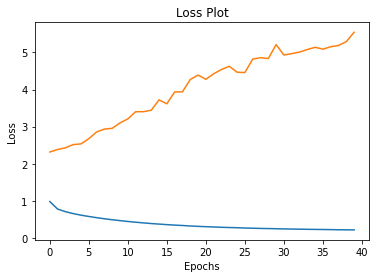

In [63]:
plt.plot(loss_plot)
plt.plot(test_loss_plot)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Plot')
plt.show()

## Inferences
- Train  loss goes down on every Epoch due to Teacher forcing.
- Test loss initially is less due to random predictions but eventually rises mostly because the model is training with teacher forcing where as test data set is new for the model to infer

# Model Evaluation
1.Evaluation function using greedy search: Chooses the most probable word in every time step of RNN output. May lead to sub-optimal results as even other words could be the right contenders in a given context

2.Evaluation function using beam search ( optional)

3.Testing it on a sample data using BLEU score

In [192]:
# for calculating BLEU score between actual and predicted captions
from nltk.translate.bleu_score import sentence_bleu

### Greedy Search

In [193]:
# A small utility to get the max length of a caption vector
def get_max_caption_len():
  max_caption_len = 0
  for k in caption_vector_map:
    if len(caption_vector_map[k]) > max_caption_len:
      max_caption_len = len(caption_vector_map[k])
  return max_caption_len

In [194]:
max_length = get_max_caption_len()
attention_features_shape = 64

def evaluate(image):
    attention_plot = np.zeros((max_length, attention_features_shape))

    hidden = decoder.init_state(batch_size=1)

    
    temp_input = tf.expand_dims(load_image(image)[0], 0) #process the input image to desired format before extracting features
    img_tensor_val = image_features_extract_model(temp_input)# Extract features using our feature extraction model
    img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))

    features = encoder(img_tensor_val)# extract the features by passing the input to encoder

    dec_input = tf.expand_dims([tokenizer.word_index['<start>']], 0)
    result = []

    for i in range(max_length):
        predictions, hidden, attention_weights = decoder([dec_input, features, hidden])# get the output from decoder

        attention_plot[i] = tf.reshape(attention_weights, (-1, )).numpy()

        # The GREEDINESS is here. We choose the word with highest value among the logits
        predicted_id = tf.argmax(predictions, 1).numpy()[0]#extract the predicted id(embedded value) which carries the max value
        #map the id to the word from tokenizer and append the value to the result list
        result.append(tokenizer.index_word[predicted_id])

        if tokenizer.index_word[predicted_id] == '<end>':
            return result, attention_plot,predictions

        dec_input = tf.expand_dims([predicted_id], 0)

    attention_plot = attention_plot[:len(result), :]
    return result, attention_plot,predictions


In [195]:
# get average caption size
avg_caption_size = sum([len(c) for c in df.Captions])//df.shape[0]
print(f'Average caption size: {avg_caption_size}')

# get index of <end> token
end_token_index = tokenizer.word_index['<end>']
print(f'<end> token index: {end_token_index}')

start_token_index = tokenizer.word_index['<start>']
print(f'<start> token index: {start_token_index}')

Average caption size: 69
<end> token index: 4
<start> token index: 3


In [196]:
def filt_text(text):
    filt=['<start>','<UNK>','<end>'] 
    temp= text.split()
    [temp.remove(j) for k in filt for j in temp if k==j]
    text=' '.join(temp)
    return text

### Beam Search(optional)
- In beam search, we gather top N (beam_index) predictions based on their logit value score.
- In each and every step we gather top N words and accumulate N set of captions.
- Using BLEU Score we choose the best among the selected captions

In [197]:
def beam_search_predict(image, real_caption, beam_index=3):
  
  hidden = decoder.init_state(batch_size=1)
  temp_input = tf.expand_dims(load_image(image)[0], 0) #process the input image to desired format before extracting features
  img_tensor_val = image_features_extract_model(temp_input)# Extract features using our feature extraction model
  img_tensor_val = tf.reshape(img_tensor_val, (img_tensor_val.shape[0], -1, img_tensor_val.shape[3]))

  features = encoder(img_tensor_val)# extract the features by passing the input to encoder

  # work queue will have utmost N records of the format [(current_caption, current_pred_word_index, current_hidden, current_caption_score)]
  first_work_item = (['<start>'],start_token_index, hidden, 0)
  work_queue = [first_work_item]
  max_cap_len = get_max_caption_len()
  max_caption_collected = 0
  # noticed that very long captions tend to get meaningless with repetetive words
  # hence restring it to actual caption size multiplied by a factor
  # lets give a 30% more margin for prediction to help the model complete the sentence.
  factor = 1.3
  caption_size_limit = int(len(real_caption.split())*factor) 

  any_more_predictions_left = True
  # while we have items to process
  while (max_caption_collected < caption_size_limit) and any_more_predictions_left:
    # create a list of work queue items that we need next
    next_work_items = []
    # iterate through work items
    for iter, work_item in enumerate(work_queue):
      work_item_caption = work_item[0]
      work_item_pred_word_index = int(work_item[1])
      work_item_hidden = work_item[2]
      # if we encountered <end> word, stop processing this sentence
      if work_item_pred_word_index == end_token_index:
        continue
      
      # even if we are crossing the actual caption length, stop here
      if len(work_item_caption) >= caption_size_limit:
        continue
      
      work_item_caption_score = work_item[3]
      
      # form the decoder input
      dec_input = tf.expand_dims([work_item_pred_word_index], 0)

      predictions, hidden, attention_weights = decoder([dec_input, features, work_item_hidden])
      # predict
      # unlike greedy search we collect the top N ('beam_index') words and test the model by splitting our options into N beams
      predicted_ids = tf.argsort(predictions, 1)[0].numpy()[-(beam_index):]
      # iterate through the top N predictions and collect 
      # [(current_caption, current_pred_word, score)] as a record
      
      for predicted_id in predicted_ids:
        # get the current predicted word 
        current_pred_word = tokenizer.index_word[predicted_id]
        current_pred_word_score = predictions[0][predicted_id].numpy()
        
        # current_caption is obtained by join
        current_caption = []
        current_caption.extend(work_item_caption)
        current_caption.append(current_pred_word)
        current_caption_score = work_item_caption_score + current_pred_word_score

        next_work_items.append((current_caption, predicted_id, hidden, current_caption_score))
      
    # assign the new set of work items if present, else reset the work_queue
    if  len(next_work_items) > 0:
      # out the 3 * 3 predictions, pick the N (beam_index) items with best score
      next_work_items.sort(key = lambda x: x[3], reverse=True)
      work_queue = next_work_items[: beam_index]
    # next set of work items not present
    else:
      any_more_predictions_left = False
    
    max_caption_collected = 0
    for w in work_queue:
      if len(w[0]) > max_caption_collected:
        max_caption_collected = len(w[0])

  # collect all the captions in a list
  captions_list = []
  for work_item in work_queue:
    captions_list.append(' '.join(work_item[0]))
  #print(f'captions_list: {captions_list}')
  return captions_list

## A method to get the best caption along with its BLEU Score

In [198]:
# gets the best caption obtained out of Beam search along with its BLEU Score
def beam_evaluate(image, real_caption, beam_index = 3):
  # code for beam search
  caption_list = beam_search_predict(
          image,
          real_caption,
          beam_index)  
  real_caption = filt_text(real_caption) 
  real_appn = []
  real_appn.append(real_caption.split())
  reference = real_appn
  best_bleu_score = 0.0
  best_caption_index = 0
  # pick the caption with best BLEU score
  for i, pred_caption in enumerate(caption_list):
    pred_caption = ' '.join(result).rsplit(' ', 1)[0]
    candidate = pred_caption.split()
    score = sentence_bleu(reference, candidate, weights=[0.5,0.5])
    if score > best_bleu_score:
      best_bleu_score = score
      best_caption_index = i

  final_caption = caption_list[best_caption_index]
  return final_caption, best_bleu_score

In [199]:
def plot_attmap(caption, weights, image):

    fig = plt.figure(figsize=(10, 10))
    temp_img = np.array(Image.open(image))
    
    len_cap = len(caption)
    nrows = len_cap//2
    ncols =  len_cap//2
    if len_cap % 2 != 0:
      nrows = nrows + 1
      ncols = ncols + 1
    for cap in range(len_cap):
        weights_img = np.reshape(weights[cap], (8,8))
        weights_img = np.array(Image.fromarray(weights_img).resize((224, 224), Image.LANCZOS))
        
        ax = fig.add_subplot(nrows, ncols, cap+1)
        ax.set_title(caption[cap], fontsize=15)
        
        img=ax.imshow(temp_img)
        
        ax.imshow(weights_img, cmap='gist_heat', alpha=0.6,extent=img.get_extent())
        ax.axis('off')
    plt.subplots_adjust(hspace=0.2, wspace=0.2)
    plt.show()

## Prediction using test data

In [200]:
test_images_count = len(path_test)
rid1 = np.random.randint(test_images_count)
rid2 = np.random.randint(test_images_count)

test_images_paths = [
    drive_path + data_folder + '/Images/2596514158_c516e57974.jpg',
    drive_path + data_folder + '/Images/2780087302_6a77658cbf.jpg'
]
test_images_paths = [
    path_test[rid1],
    path_test[rid2]
]

print('-'*80)
print('Images should come from train dataset:')
for ti in test_images_paths:
  print(f'Image {ti } is in test data: {ti in path_test}')

print('\nImages should NOT come from train dataset:')
for ti in test_images_paths:
  print(f'Image {ti } is in train data: {ti in path_train}')
print('-'*80)

for ti in test_images_paths:
  print('-'*80)
  print(f'Captions of image {ti}:')
  captions = list(df[df.Path == ti]['Captions'])
  for c in captions:
    print(f'- {c}')
  print('-'*80)

--------------------------------------------------------------------------------
Images should come from train dataset:
Image ./archive/Images/3435015880_eda46ff50f.jpg is in test data: True
Image ./archive/Images/3371887001_44ab0c2f17.jpg is in test data: True

Images should NOT come from train dataset:
Image ./archive/Images/3435015880_eda46ff50f.jpg is in train data: False
Image ./archive/Images/3371887001_44ab0c2f17.jpg is in train data: False
--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Captions of image ./archive/Images/3435015880_eda46ff50f.jpg:
- <start> a guy and a girl jumping up in the air <end>
- <start> a man and a woman are running and jumping on top of a hill . <end>
- <start> two people are running at the top of a mountain . <end>
- <start> two people jump up and down on a cliff overlooking a valley . <end>
- <start> two women jump in the grass atop a mou

In [201]:
captions1 = list(df[df.Path == test_images_paths[0]]['Captions'])[0]
captions2 = list(df[df.Path == test_images_paths[1]]['Captions'])[0]
real_captions = [captions1, captions2]

Path of the Image selected ./archive/Images/3435015880_eda46ff50f.jpg
Caption of the Image selected <start> a guy and a girl jumping up in the air <end>
BLEU score: 17.410441154600917
Real Caption: a guy and a girl jumping up in the air
Prediction Caption: a man jumps in the grass mountains


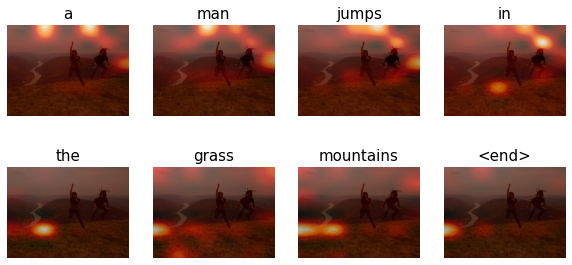

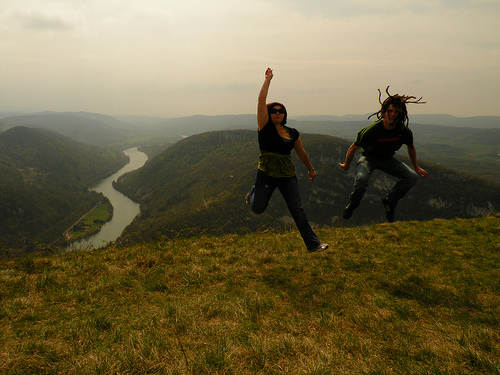

In [202]:
test_image_path = test_images_paths[0]
real_caption = real_captions[0]

print(f'Path of the Image selected {test_image_path}')
print(f'Caption of the Image selected {real_caption}')

test_image = get_image_tensor(test_image_path)
result, attention_plot,pred_test = evaluate(test_image_path)

real_caption=filt_text(real_caption)      

pred_caption=' '.join(result).rsplit(' ', 1)[0]

real_appn = []
real_appn.append(real_caption.split())
reference = real_appn
candidate = pred_caption.split()

#set weights for blue score (we will be usng bigrams)
score = sentence_bleu(reference, candidate, weights=[0.5, 0.5])
print(f"BLEU score: {score*100}")

print ('Real Caption:', real_caption)
print ('Prediction Caption:', pred_caption)
plot_attmap(result, attention_plot, test_image_path)

Image.open(test_image_path)

Path of the Image selected ./archive/Images/3371887001_44ab0c2f17.jpg
Caption of the Image selected <start> a man in a dark outfit and sunglasses is riding a mountain bike through a forest near a stream . <end>
BLEU score: 4.817907476357601
Real Caption: a man in a dark outfit and sunglasses is riding a mountain bike through a forest near a stream .
Prediction Caption: a man is going down a hill


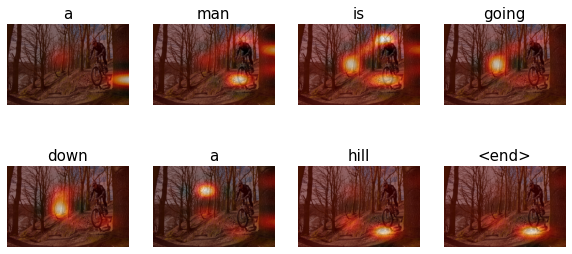

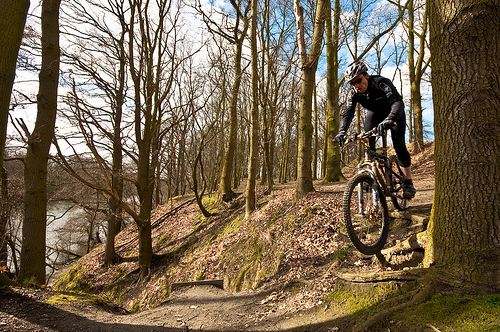

In [203]:
test_image_path = test_images_paths[1]
real_caption = real_captions[1]

print(f'Path of the Image selected {test_image_path}')
print(f'Caption of the Image selected {real_caption}')

test_image = get_image_tensor(test_image_path)
result, attention_plot,pred_test = evaluate(test_image_path)

real_caption=filt_text(real_caption)      

pred_caption=' '.join(result).rsplit(' ', 1)[0]

real_appn = []
real_appn.append(real_caption.split())
reference = real_appn
candidate = pred_caption.split()

#set weights for blue score (we will be usng bigrams)
score = sentence_bleu(reference, candidate, weights=[0.5, 0.5])
print(f"BLEU score: {score*100}")

print ('Real Caption:', real_caption)
print ('Prediction Caption:', pred_caption)
plot_attmap(result, attention_plot, test_image_path)

Image.open(test_image_path)

## Inferences
- Start to End in predicted with Attention weights overlayed on the Image.
- The model seems to do a fine. However it can be better.

## Predictions using Beam search

In [204]:
# beam search function
def beam_search(image_path, real_caption, beam_index = 3):
  tw = textwrap.TextWrapper(width = 80)
  caption_wrapped = tw.wrap(text = real_caption)
  print(f'Real Caption:')
  for c in caption_wrapped:
    print(c)
  print(f'*'*80)
  caption, score = beam_evaluate(image_path, real_caption, beam_index)
  print(f"BLEU score: {score*100}")
  caption_wrapped = tw.wrap(text = caption)
  print(f'Prediction with Beam Search with beam_index {beam_index}:')
  for c in caption_wrapped:
    print(c)
  print(f'-'*80)

## Beam Index = 3

In [205]:
for i, test_image_path in enumerate(test_images_paths):
  print('test_image_path',test_image_path)
  real_caption = real_captions[i]
  beam_search(test_image_path, real_caption, 3)

test_image_path ./archive/Images/3435015880_eda46ff50f.jpg
Real Caption:
<start> a guy and a girl jumping up in the air <end>
********************************************************************************
BLEU score: 5.194120096460954e-153
Prediction with Beam Search with beam_index 3:
<start> there is guy stands on the grass on his shoulders and orange swim trunks
--------------------------------------------------------------------------------
test_image_path ./archive/Images/3371887001_44ab0c2f17.jpg
Real Caption:
<start> a man in a dark outfit and sunglasses is riding a mountain bike through
a forest near a stream . <end>
********************************************************************************
BLEU score: 4.817907476357601
Prediction with Beam Search with beam_index 3:
<start> someone is going down a hill holding onto a mountain bike in a wooded
surrounded by attached to photos on a mountain bike in the woods <end>
----------------------------------------------------------

## Beam Index = 5

In [206]:
for i, test_image_path in enumerate(test_images_paths):
  real_caption = real_captions[i]
  beam_search(test_image_path, real_caption, 5)

Real Caption:
<start> a guy and a girl jumping up in the air <end>
********************************************************************************
BLEU score: 5.194120096460954e-153
Prediction with Beam Search with beam_index 5:
<start> there is guy stands on the grass mountains on his shoulders lying in the
--------------------------------------------------------------------------------
Real Caption:
<start> a man in a dark outfit and sunglasses is riding a mountain bike through
a forest near a stream . <end>
********************************************************************************
BLEU score: 4.817907476357601
Prediction with Beam Search with beam_index 5:
<start> someone is going down the hill in a wooded area while going down the
hill in rural area while going down an outside of leafless trees holding
--------------------------------------------------------------------------------


## Beam Index = 7

In [207]:
for i, test_image_path in enumerate(test_images_paths):
  real_caption = real_captions[i]
  beam_search(test_image_path, real_caption, 7)

Real Caption:
<start> a guy and a girl jumping up in the air <end>
********************************************************************************
BLEU score: 5.194120096460954e-153
Prediction with Beam Search with beam_index 7:
<start> there is leaps into the bright blue jeans is standing on her shoulders
and
--------------------------------------------------------------------------------
Real Caption:
<start> a man in a dark outfit and sunglasses is riding a mountain bike through
a forest near a stream . <end>
********************************************************************************
BLEU score: 4.817907476357601
Prediction with Beam Search with beam_index 7:
<start> someone is going alone going down the hill in rural area surrounded by
attached to someone else biking near a wooded area while going down the hill
--------------------------------------------------------------------------------


## Inferences
- Greeedy search prediction was fine.
- Predictions by beam search seems to have more words but not necessarily accurate
- As we expand the beam index, the predictions tend to generalise a lot